# Week 01: Small Python Data-Processing App

## Introduction

This project demonstrates how to load a raw dataset, clean it using reusable Python functions, and process numerical data with NumPy.

The dataset contains student names and scores. It includes missing values, duplicate records, and invalid scores so that the cleaning process can be demonstrated.

## Objectives

- Load raw CSV data.
- Clean the data using functions.
- Process numerical values with NumPy.
- Calculate descriptive statistics.
- Visualize the cleaned student scores.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

## 1. Loading the Raw Dataset

The dataset is stored as CSV-formatted text. StringIO allows pandas to read the text as if it were a file.

This makes the notebook self-contained, so it can run in Google Colab without requiring a separate CSV upload.

In [2]:
csv_data = """name,score
Amina,85
Sara,72
Hana,NA
Abdi,95
Amina,85
Yusuf,110
Mekdes,60
Liya,78
,88
Omar,45
"""

raw_data = pd.read_csv(
    StringIO(csv_data),
    na_values=["NA", ""]
)

print("Raw dataset:")
display(raw_data)

Raw dataset:


,name,score
0,Amina,85.0
1,Sara,72.0
2,Hana,NaN
3,Abdi,95.0
4,Amina,85.0
5,Yusuf,110.0
6,Mekdes,60.0
7,Liya,78.0
8,NaN,88.0
9,Omar,45.0


## 2. Cleaning the Dataset

Data cleaning helps improve data quality before analysis.

In this project, the cleaning function:
- Removes records with missing or empty names.
- Converts scores into numeric values.
- Removes records with missing scores.
- Keeps scores between 0 and 100.
- Removes duplicate records.
- Resets the row index.

In [3]:
def clean_data(df):
    """Clean missing, invalid, and duplicate records."""
    df = df.copy()

    df["name"] = df["name"].astype("string").str.strip()
    df = df.dropna(subset=["name"])
    df = df[df["name"] != ""]

    df["score"] = pd.to_numeric(
        df["score"],
        errors="coerce"
    )

    df = df.dropna(subset=["score"])
    df = df[df["score"].between(0, 100)]
    df = df.drop_duplicates()

    return df.reset_index(drop=True)


cleaned_data = clean_data(raw_data)

print("Cleaned dataset:")
display(cleaned_data)

Cleaned dataset:


,name,score
0,Amina,85.0
1,Sara,72.0
2,Abdi,95.0
3,Mekdes,60.0
4,Liya,78.0
5,Omar,45.0


## 3. Processing Data with NumPy

NumPy provides efficient operations for numerical data.

The score column is converted into a NumPy array. We then calculate:
- Number of valid students
- Average score
- Highest score
- Lowest score
- Pass rate, using 50 as the passing threshold

In [4]:
def process_data(df):
    """Calculate statistics using NumPy."""
    scores = df["score"].to_numpy(dtype=float)

    if scores.size == 0:
        raise ValueError("No valid scores remain after cleaning.")

    return {
        "total_students": int(scores.size),
        "average_score": float(np.mean(scores)),
        "highest_score": float(np.max(scores)),
        "lowest_score": float(np.min(scores)),
        "pass_rate": float(np.mean(scores >= 50) * 100),
    }


results = process_data(cleaned_data)

for key, value in results.items():
    label = key.replace("_", " ").title()

    if key in ("average_score", "pass_rate"):
        print(f"{label}: {value:.2f}")
    else:
        print(f"{label}: {value}")

Total Students: 6
Average Score: 72.50
Highest Score: 95.0
Lowest Score: 45.0
Pass Rate: 83.33


## 4. Visualizing Student Scores

A bar chart makes it easier to compare the scores of the students who remain after cleaning.

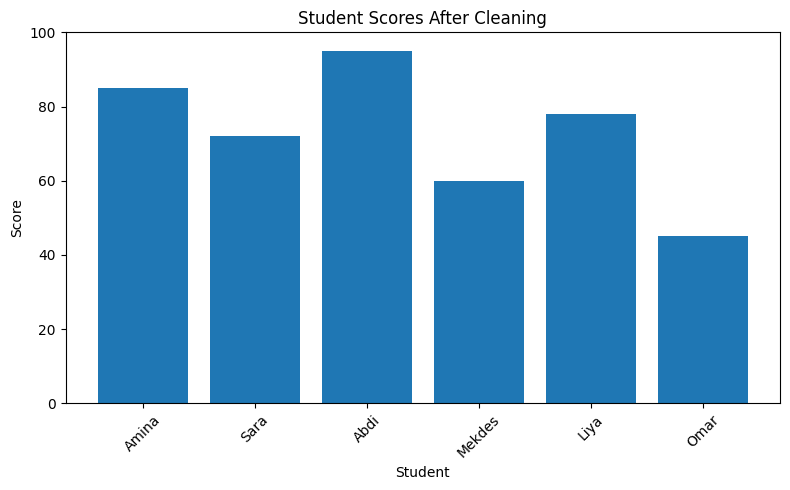

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(
    cleaned_data["name"],
    cleaned_data["score"]
)

plt.title("Student Scores After Cleaning")
plt.xlabel("Student")
plt.ylabel("Score")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Conclusion

This project demonstrates a basic data-processing workflow using Python, pandas, and NumPy.

The raw dataset was loaded and cleaned before the statistical calculations were performed. The results show six valid student records, an average score of 72.50, a highest score of 95, a lowest score of 45, and a pass rate of 83.33%.

The project helped demonstrate the importance of data quality, reusable functions, numerical processing, and data visualization.